# Universidad Católica de Salta — Facultad de Ingeniería
## Investigación Operativa II (2026) — Trabajo Final Integrador
### Sistema de turnos dinámicos con recomendación de vacantes para las asambleas de designación docente en Salta

**Integrantes:** Emiliano Javier Aguirre (DNI 45.770.631) y Pablo Celaya (DNI 45.115.839)  
**Docentes:** Mg. Ing. Gustavo Ramiro Rivadera · Ing. Gustavo Flores Vargas  

Este notebook reproduce de forma interactiva y modular:
1. La verificación analítica del motor de eventos discretos contra las fórmulas teóricas de $M/M/1$ y $M/M/c$.
2. La calibración del recomendador multicriterio (*Hit Rate@3* y *Hit Rate@1*) y la evaluación del pronóstico Monte Carlo ($MSE$/$RMSE$).
3. La simulación y comparación de los 3 escenarios principales (E1, E2 y E3) sobre las 30 réplicas independientes con pruebas de hipótesis pareadas ($gl = 29$).
4. La visualización de las figuras del informe.

In [1]:
import json
import pathlib
import pandas as pd
from IPython.display import Image, display

# Detección robusta de la raíz del proyecto para ejecución desde la raíz o desde la carpeta notebooks/
cwd = pathlib.Path(".").resolve()
if (cwd / "data" / "resultados_experimentos.json").exists():
    ROOT_DIR = cwd
elif (cwd.parent / "data" / "resultados_experimentos.json").exists():
    ROOT_DIR = cwd.parent
else:
    ROOT_DIR = cwd

resultados_path = ROOT_DIR / "data" / "resultados_experimentos.json"
with open(resultados_path, "r", encoding="utf-8") as f:
    res = json.load(f)

print(f"Resultados experimentales cargados correctamente desde: {resultados_path.name}")

Resultados experimentales cargados correctamente desde: resultados_experimentos.json


---
## 1. Verificación analítica del motor de simulación ($M/M/1$ y $M/M/c$)
Contraste de las medias simuladas contra las soluciones analíticas de cátedra para validar el motor de simulación:

In [2]:
val_filas = []
for caso, datos in res["verificacion_mmc"].items():
    sim = datos["simulado"]
    teo = datos["teorico"]
    err = datos["error_rel_pct"]
    ic_ok = datos["contiene_valor_teorico"]
    val_filas.append({
        "Modelo": caso,
        "Wq simulado (h)": f"{sim['wq']['media']:.4f} ± {sim['wq']['semiamplitud']:.4f}",
        "Wq teórico (h)": f"{teo['wq']:.4f}",
        "Error Wq (%)": f"{err['wq']:.2f} %",
        "Lq simulado": f"{sim['lq']['media']:.4f} ± {sim['lq']['semiamplitud']:.4f}",
        "Lq teórico": f"{teo['lq']:.4f}",
        "IC contiene teórico": "Sí" if ic_ok["wq"] else "No"
    })

df_val = pd.DataFrame(val_filas)
display(df_val)

,Modelo,Wq simulado (h),Wq teórico (h),Error Wq (%),Lq simulado,Lq teórico,IC contiene teórico
0,"M/M/1 (lam=4, mu=6)",0.3344 ± 0.0026,0.3333,0.32 %,1.3383 ± 0.0111,1.3333,Sí
1,"M/M/1 (lam=2, mu=3)",0.6644 ± 0.0064,0.6667,0.34 %,1.3291 ± 0.0132,1.3333,Sí
2,"M/M/2 (lam=2, mu=3)",0.0418 ± 0.0004,0.0417,0.27 %,0.0835 ± 0.0009,0.0833,Sí


---
## 2. Desempeño del recomendador y del pronóstico Monte Carlo
Resultados de la grilla de pesos de recomendación y evaluación de la reducción del error cuadrático medio ($MSE$):

In [3]:
rec_info = res["recomendador_hit_rate"]
print("=== CALIBRACIÓN DEL RECOMENDADOR MULTICRITERIO ===")
print(f"Óptimo de pesos hallado: {rec_info['mejores_pesos']} (w_distancia, w_turno, w_categoria)")
print(f"Hit Rate@3 óptimo: {rec_info['hr_mejor_grilla']:.2f} %")
print(f"Hit Rate@1 óptimo: {rec_info['hr1_mejor_grilla']:.2f} %")
print(f"Hit Rate@3 al azar: {rec_info['hr_azar']:.2f} %")
print(f"Hit Rate@1 al azar: {rec_info['hr1_azar']:.2f} %")

mc_info = res["pronostico_monte_carlo"]
red_mse = (1 - mc_info['mc_mse_rep']['media'] / mc_info['base_mse_rep']['media']) * 100
print("\n=== EVALUACIÓN DEL PRONÓSTICO MONTE CARLO (PREAVISO) ===")
print(f"MSE con Monte Carlo: {mc_info['mc_mse_rep']['media']:.4f} ± {mc_info['mc_mse_rep']['semiamplitud']:.4f}")
print(f"MSE sin pronóstico:  {mc_info['base_mse_rep']['media']:.4f} ± {mc_info['base_mse_rep']['semiamplitud']:.4f}")
print(f"Reducción en MSE:    {red_mse:.1f} % (p < 0.001)")

=== CALIBRACIÓN DEL RECOMENDADOR MULTICRITERIO ===
Óptimo de pesos hallado: [0.4, 0.4, 0.2] (w_distancia, w_turno, w_categoria)
Hit Rate@3 óptimo: 97.33 %
Hit Rate@1 óptimo: 69.67 %
Hit Rate@3 al azar: 75.02 %
Hit Rate@1 al azar: 35.73 %

=== EVALUACIÓN DEL PRONÓSTICO MONTE CARLO (PREAVISO) ===
MSE con Monte Carlo: 0.0147 ± 0.0010
MSE sin pronóstico:  0.0511 ± 0.0021
Reducción en MSE:    71.3 % (p < 0.001)


---
## 3. Comparación principal entre escenarios (E1, E2 y E3)
Medias e intervalos de confianza del 95 % sobre las 30 réplicas independientes de la asamblea:

In [4]:
res_esc = res["escenarios_principales"]
comp_filas = []
for esc in ["E1", "E2", "E3"]:
    d = res_esc[esc]
    comp_filas.append({
        "Escenario": esc,
        "Wq atendidos (min)": f"{d['wq_atendidos']['media']:.2f} ± {d['wq_atendidos']['semiamplitud']:.2f}",
        "W1 primer llamado (min)": f"{d['wq_primer_turno']['media']:.2f} ± {d['wq_primer_turno']['semiamplitud']:.2f}",
        "Wconv 300 doc (min)": f"{d['w_convocados']['media']:.2f} ± {d['w_convocados']['semiamplitud']:.2f}",
        "Ttotal (horas)": f"{d['t_total_horas']['media']:.2f} h",
        "% Reintentos": f"{d['pct_reintentos']['media']:.2f} %",
        "Docentes afectados mérito": f"{d['cant_afectados_merito']['media']:.1f}",
        "Satisfacción (0-1)": f"{d['satisfaccion_media']['media']:.3f}"
    })

df_comp = pd.DataFrame(comp_filas)
display(df_comp)

,Escenario,Wq atendidos (min),W1 primer llamado (min),Wconv 300 doc (min),Ttotal (horas),% Reintentos,Docentes afectados mérito,Satisfacción (0-1)
0,E1,260.47 ± 12.07,260.47 ± 12.07,416.44 ± 15.85,9.02 h,0.00 %,0.0,0.590
1,E2,316.17 ± 16.87,271.09 ± 14.51,421.43 ± 14.25,8.98 h,16.86 %,26.7,0.609
2,E3,263.64 ± 15.49,232.73 ± 13.24,359.26 ± 13.78,7.67 h,13.71 %,21.2,0.586


---
## 4. Visualización de las figuras del informe

Mostrando: graficos/salida/fig1_boxplot_duracion_escenarios.png


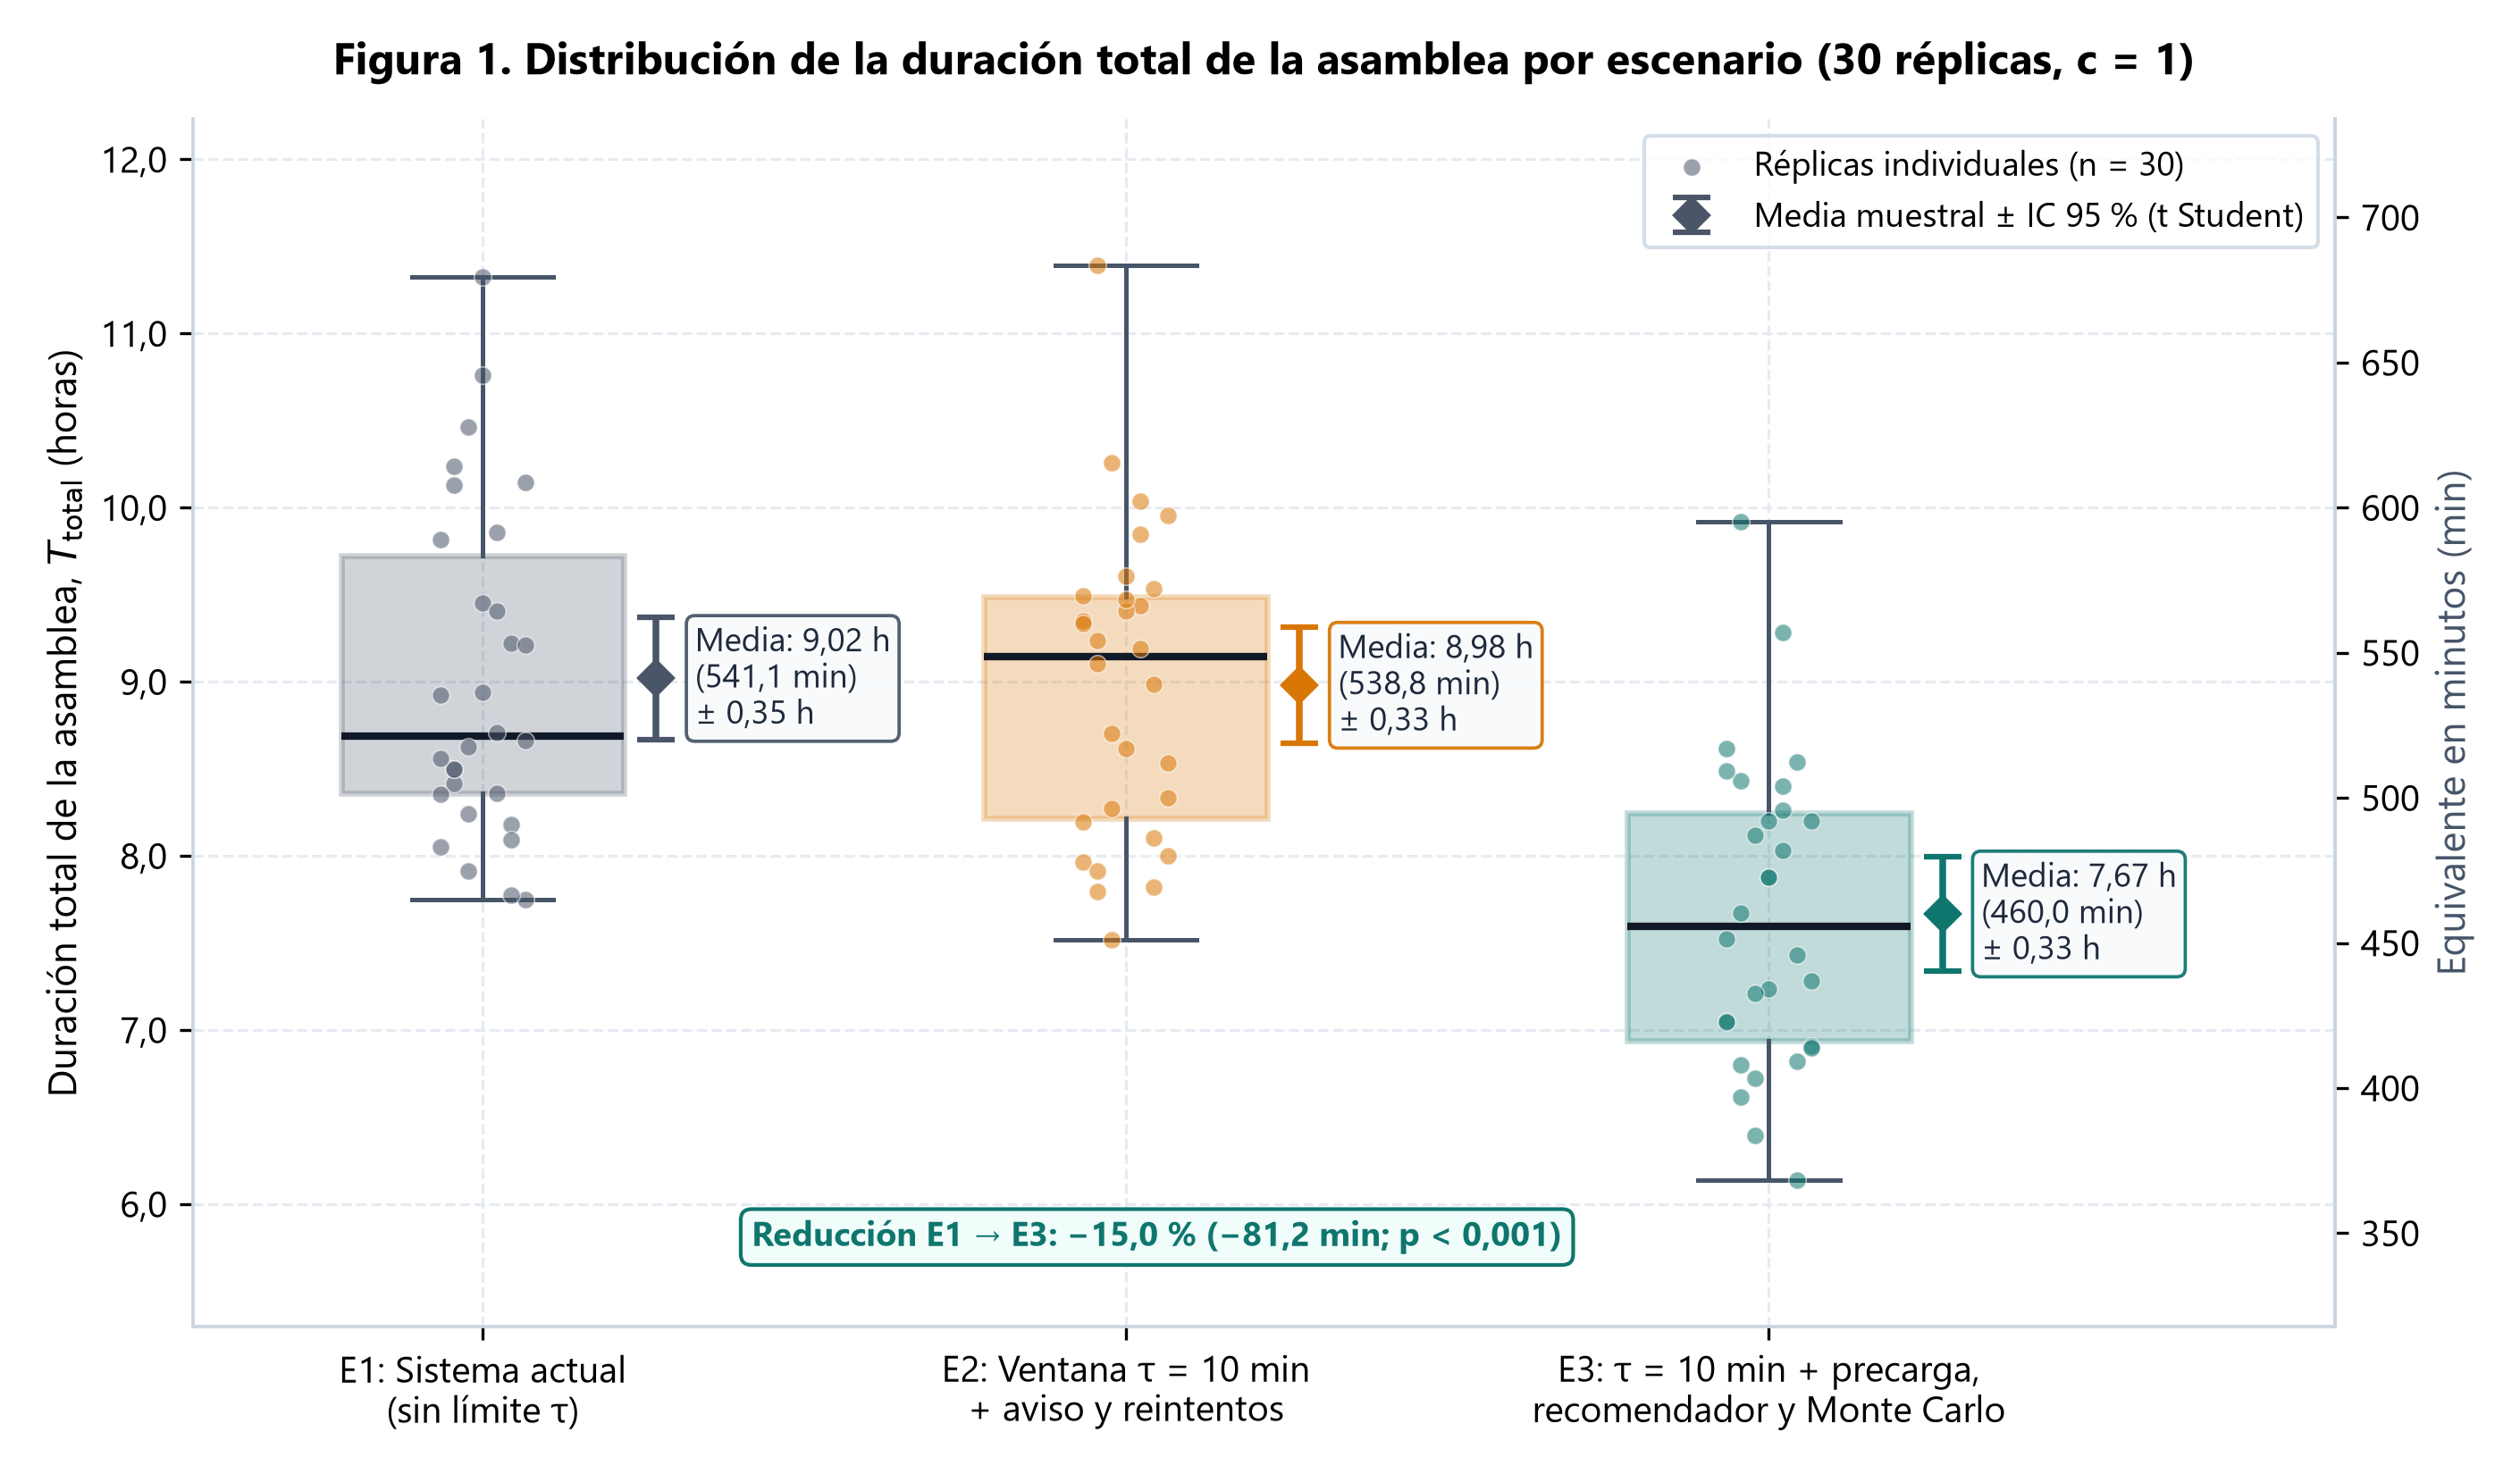

Mostrando: graficos/salida/fig2_sensibilidad_ventana_tau.png


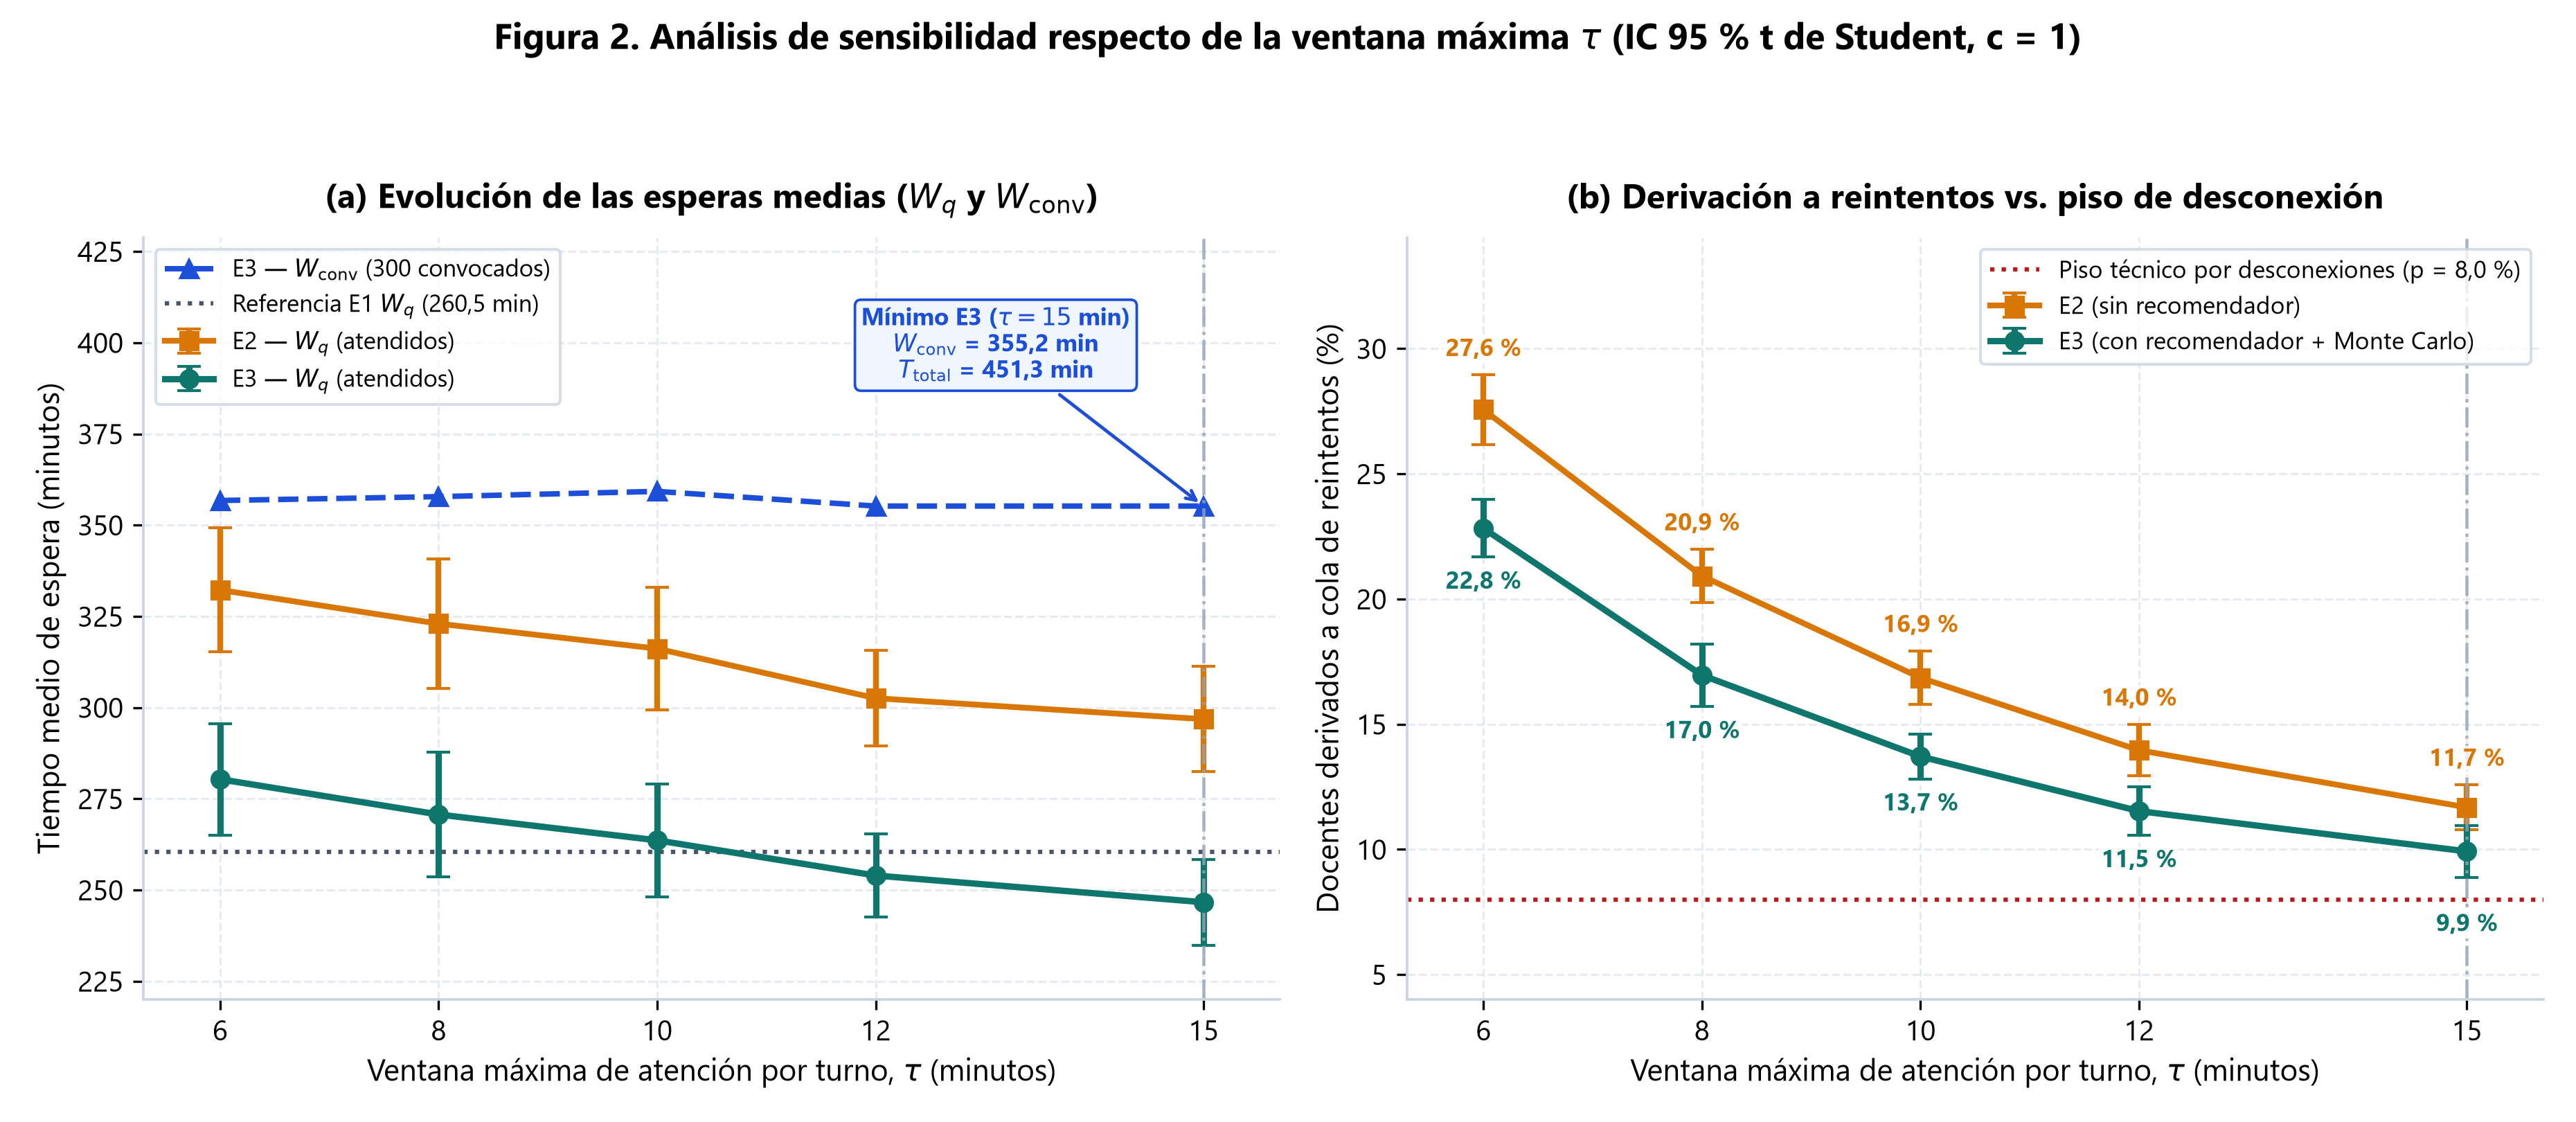

Mostrando: graficos/salida/fig3_sensibilidad_comisiones_c.png


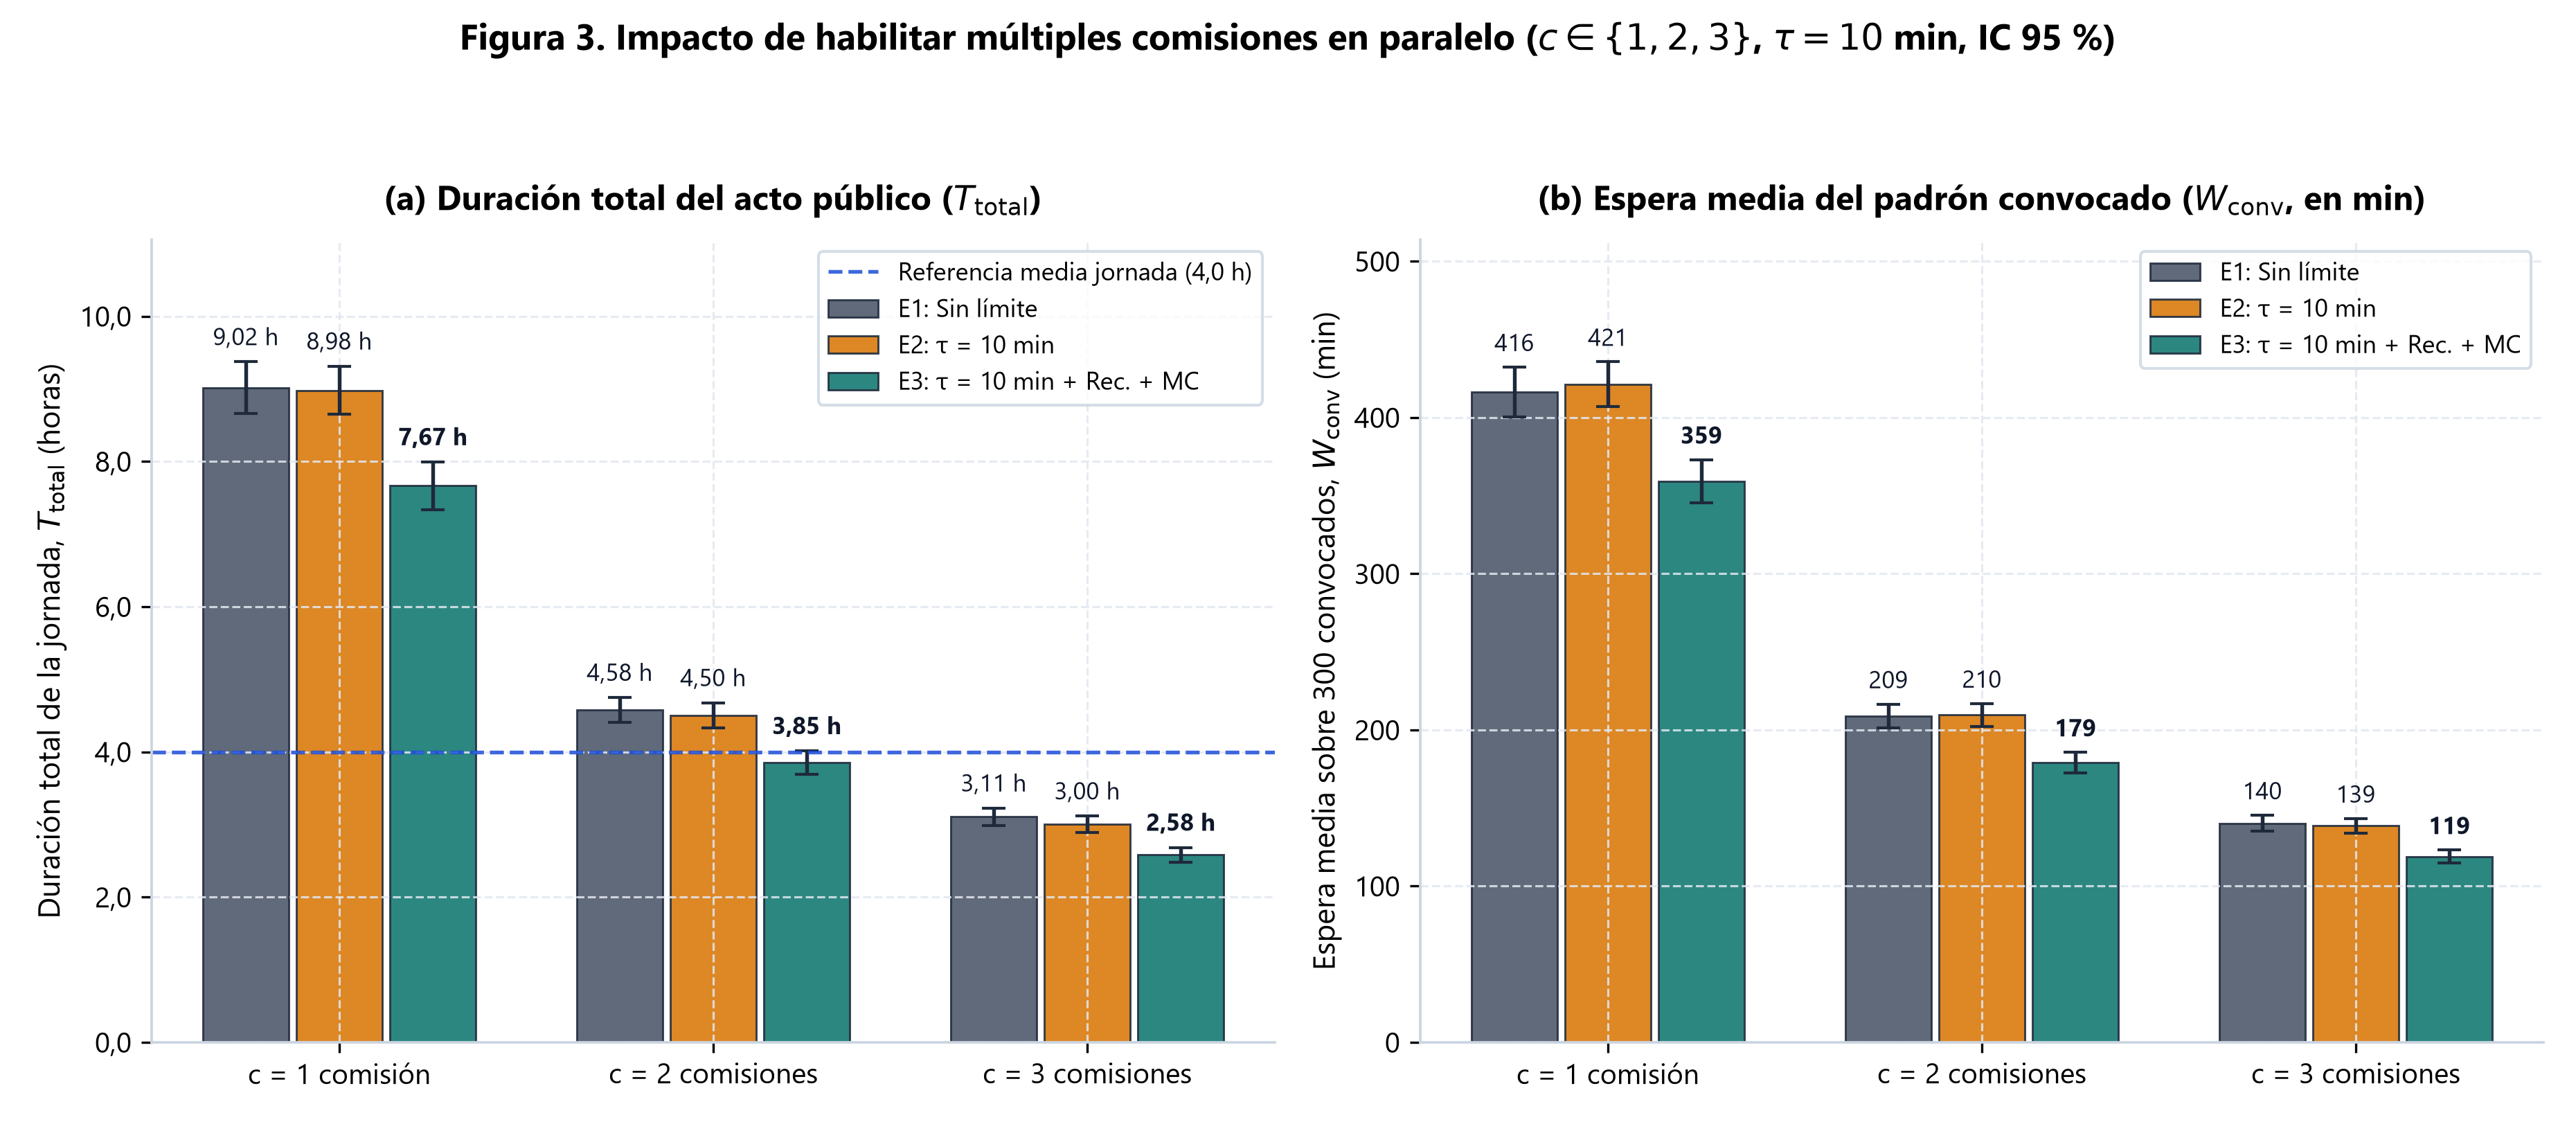

Mostrando: graficos/salida/fig4_adopcion_recomendador_y_montecarlo.png


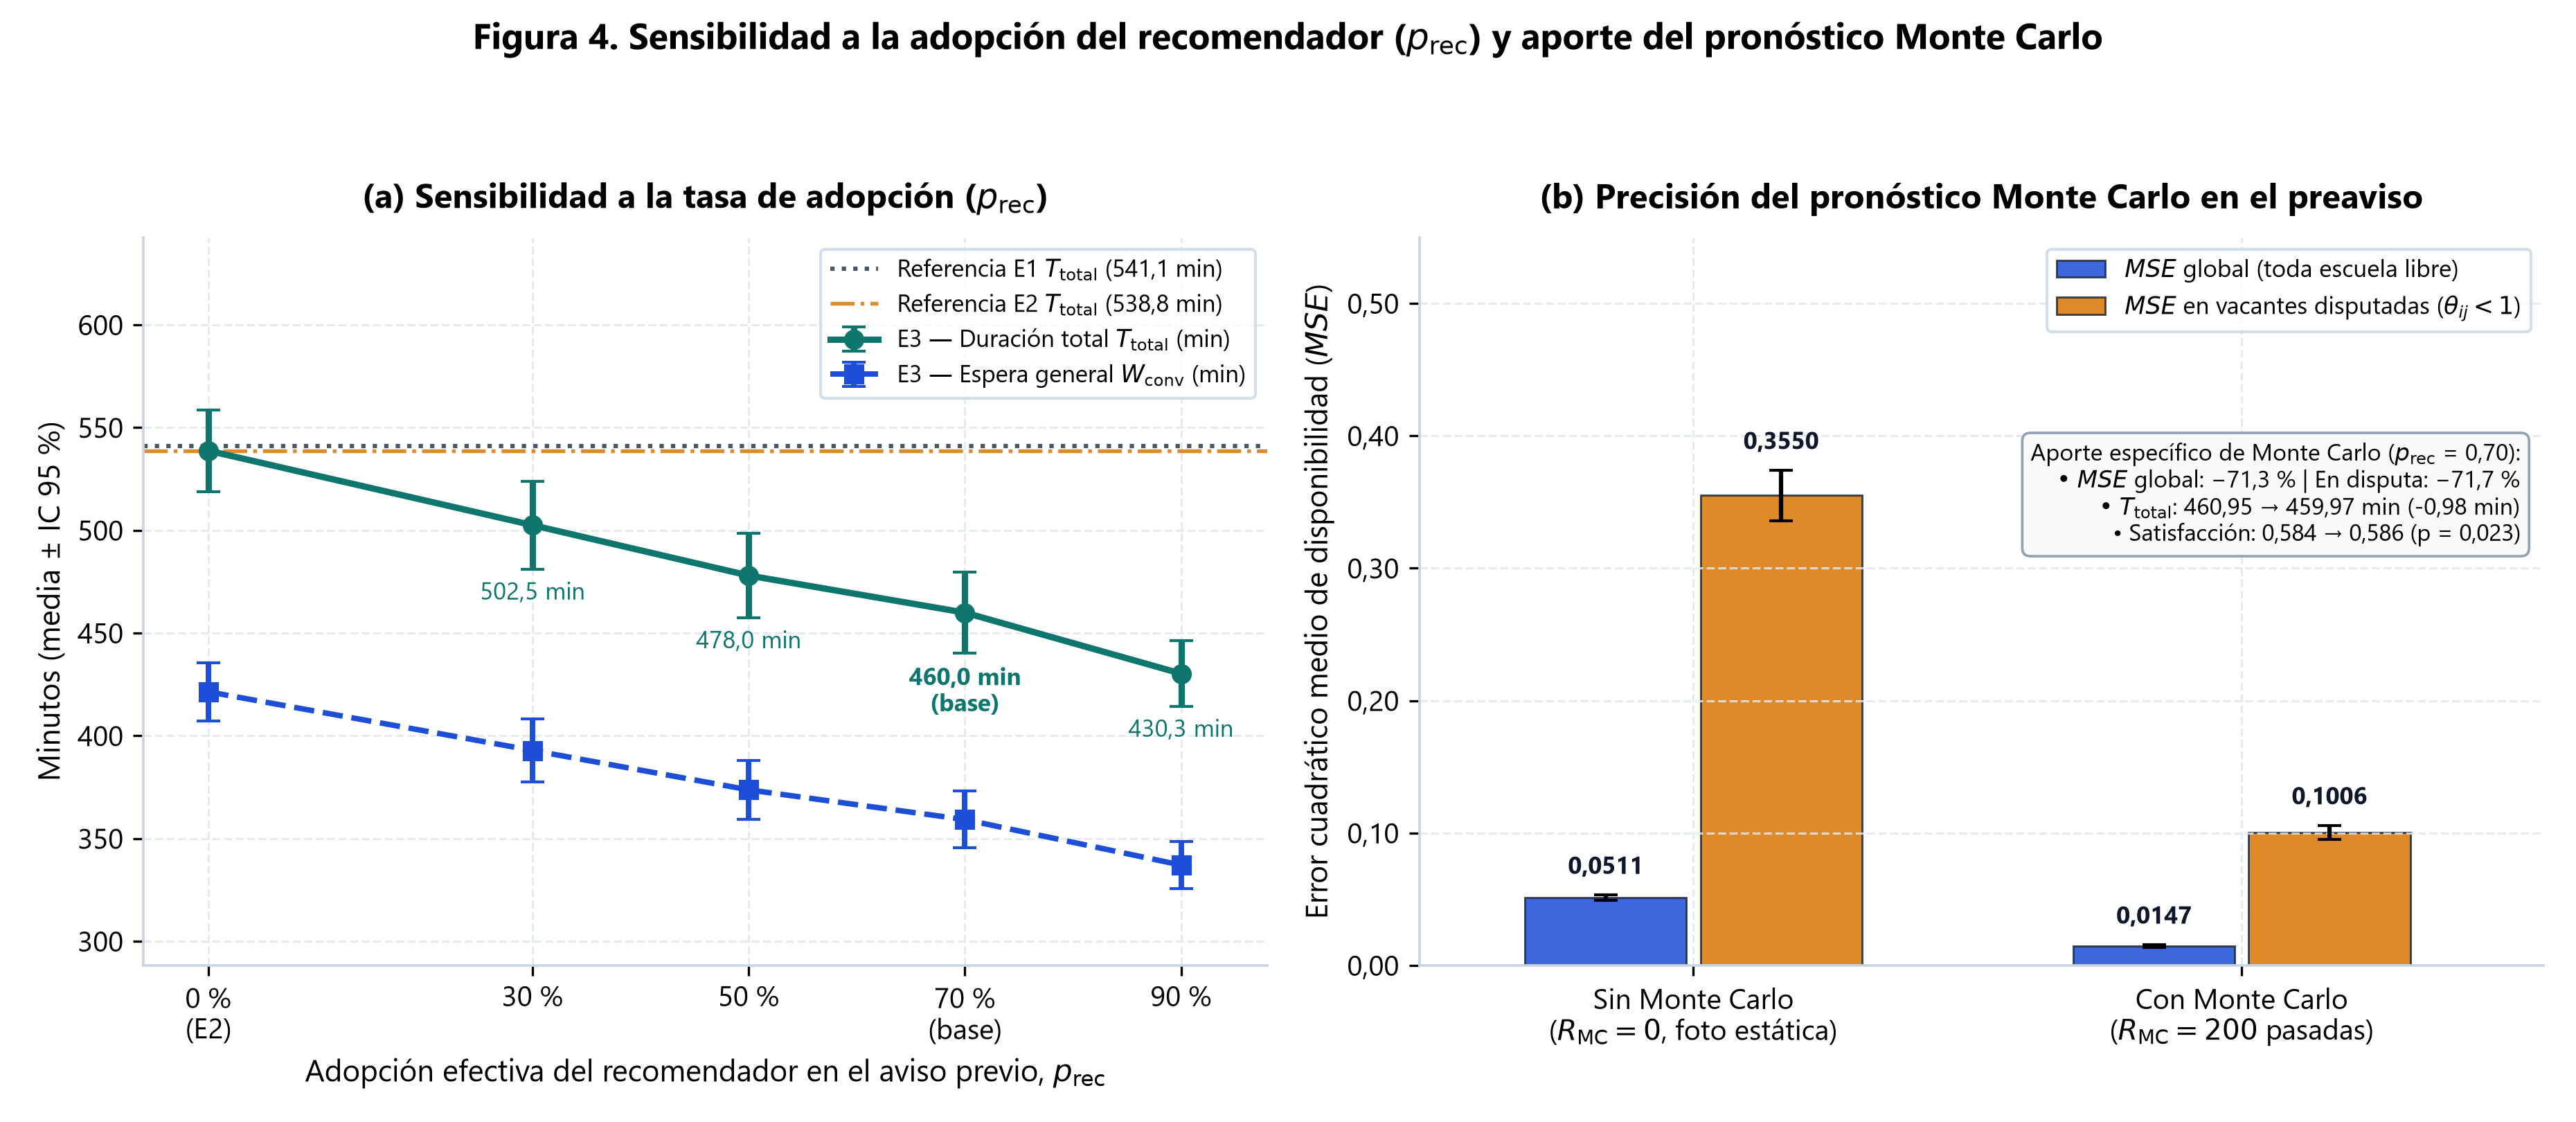

In [5]:
figuras = [
    "graficos/salida/fig1_boxplot_duracion_escenarios.png",
    "graficos/salida/fig2_sensibilidad_ventana_tau.png",
    "graficos/salida/fig3_sensibilidad_comisiones_c.png",
    "graficos/salida/fig4_adopcion_recomendador_y_montecarlo.png"
]

for rel_fig in figuras:
    fig_path = ROOT_DIR / rel_fig
    if fig_path.exists():
        print(f"Mostrando: {rel_fig}")
        display(Image(filename=str(fig_path), width=700))
    else:
        print(f"Figura no encontrada en: {fig_path}")